In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

sns.set_theme(style="whitegrid")


In [3]:
file_path = "/Users/hamidrezaasaadian/Desktop/Heart.csv"

df = pd.read_csv(file_path)

print(df.head())
print(df.shape)
print(df.columns.tolist())


   Unnamed: 0  Age  Sex     ChestPain  RestBP  Chol  Fbs  RestECG  MaxHR  \
0           1   63    1       typical     145   233    1        2    150   
1           2   67    1  asymptomatic     160   286    0        2    108   
2           3   67    1  asymptomatic     120   229    0        2    129   
3           4   37    1    nonanginal     130   250    0        0    187   
4           5   41    0    nontypical     130   204    0        2    172   

   ExAng  Oldpeak  Slope   Ca        Thal  AHD  
0      0      2.3      3  0.0       fixed   No  
1      1      1.5      2  3.0      normal  Yes  
2      1      2.6      2  2.0  reversable  Yes  
3      0      3.5      3  0.0      normal   No  
4      0      1.4      1  0.0      normal   No  
(303, 15)
['Unnamed: 0', 'Age', 'Sex', 'ChestPain', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'MaxHR', 'ExAng', 'Oldpeak', 'Slope', 'Ca', 'Thal', 'AHD']


In [4]:
column_names = [
    "ID", "Age", "Sex", "ChestPain", "RestBP",
    "Chol", "Fbs", "RestECG", "MaxHR", "ExAng",
    "Oldpeak", "Slope", "Ca", "Thal", "AHD"
]

df = pd.read_csv(
    file_path,
    header=None,
    skiprows=1,
    names=column_names
)

print(df.head())
print(df.columns.tolist())


   ID  Age  Sex     ChestPain  RestBP  Chol  Fbs  RestECG  MaxHR  ExAng  \
0   1   63    1       typical     145   233    1        2    150      0   
1   2   67    1  asymptomatic     160   286    0        2    108      1   
2   3   67    1  asymptomatic     120   229    0        2    129      1   
3   4   37    1    nonanginal     130   250    0        0    187      0   
4   5   41    0    nontypical     130   204    0        2    172      0   

   Oldpeak  Slope   Ca        Thal  AHD  
0      2.3      3  0.0       fixed   No  
1      1.5      2  3.0      normal  Yes  
2      2.6      2  2.0  reversable  Yes  
3      3.5      3  0.0      normal   No  
4      1.4      1  0.0      normal   No  
['ID', 'Age', 'Sex', 'ChestPain', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'MaxHR', 'ExAng', 'Oldpeak', 'Slope', 'Ca', 'Thal', 'AHD']


In [5]:
numeric_columns = [
    "ID", "Age", "RestBP", "Chol", "Fbs",
    "RestECG", "MaxHR", "ExAng", "Oldpeak",
    "Slope", "Ca"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")


In [6]:
categorical_columns = ["Sex", "ChestPain", "Thal"]

for column in categorical_columns:
    df[column] = df[column].astype("string").str.strip()


In [7]:
df["AHD"] = (
    df["AHD"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({
        "no": 0,
        "yes": 1,
        "0": 0,
        "1": 1
    })
)


In [8]:
df = df.drop(columns=["ID"], errors="ignore")


In [11]:
df = df.dropna(subset=["AHD"])
df["AHD"] = df["AHD"].astype(int)
df= df.dropna()

print(df.head())
print(df.info())


   Age Sex     ChestPain  RestBP  Chol  Fbs  RestECG  MaxHR  ExAng  Oldpeak  \
0   63   1       typical     145   233    1        2    150      0      2.3   
1   67   1  asymptomatic     160   286    0        2    108      1      1.5   
2   67   1  asymptomatic     120   229    0        2    129      1      2.6   
3   37   1    nonanginal     130   250    0        0    187      0      3.5   
4   41   0    nontypical     130   204    0        2    172      0      1.4   

   Slope   Ca        Thal  AHD  
0      3  0.0       fixed    0  
1      2  3.0      normal    1  
2      2  2.0  reversable    1  
3      3  0.0      normal    0  
4      1  0.0      normal    0  
<class 'pandas.core.frame.DataFrame'>
Index: 297 entries, 0 to 301
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Age        297 non-null    int64  
 1   Sex        297 non-null    string 
 2   ChestPain  297 non-null    string 
 3   RestBP     297 non-nul

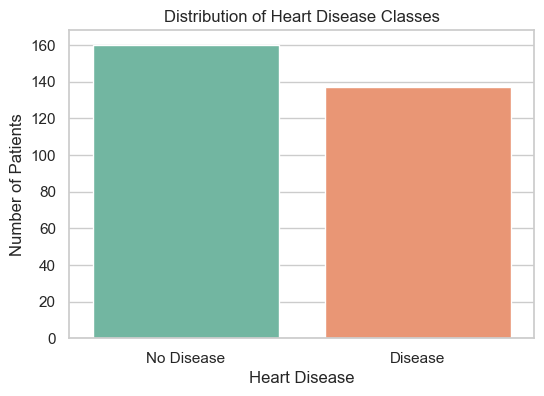

In [12]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="AHD",
    hue="AHD",
    palette="Set2",
    legend=False
)

plt.xticks([0, 1], ["No Disease", "Disease"])
plt.title("Distribution of Heart Disease Classes")
plt.xlabel("Heart Disease")
plt.ylabel("Number of Patients")
plt.show()


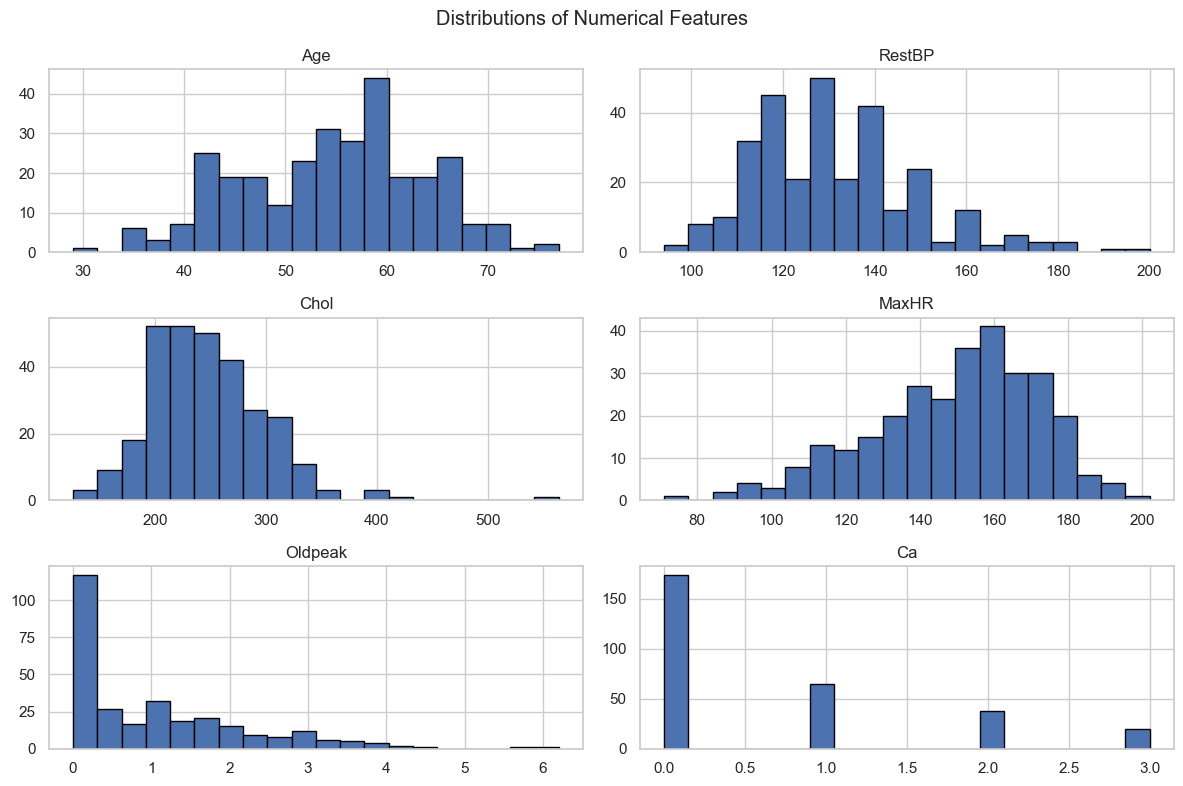

In [13]:
numeric_features = [
    "Age", "RestBP", "Chol",
    "MaxHR", "Oldpeak", "Ca"
]

df[numeric_features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distributions of Numerical Features")
plt.tight_layout()
plt.show()


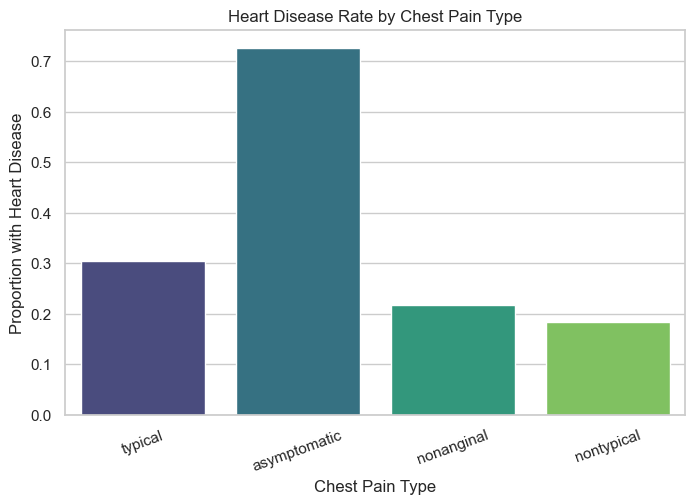

In [14]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="ChestPain",
    y="AHD",
    estimator="mean",
    errorbar=None,
    hue="ChestPain",
    legend=False,
    palette="viridis"
)

plt.title("Heart Disease Rate by Chest Pain Type")
plt.xlabel("Chest Pain Type")
plt.ylabel("Proportion with Heart Disease")
plt.xticks(rotation=20)
plt.show()


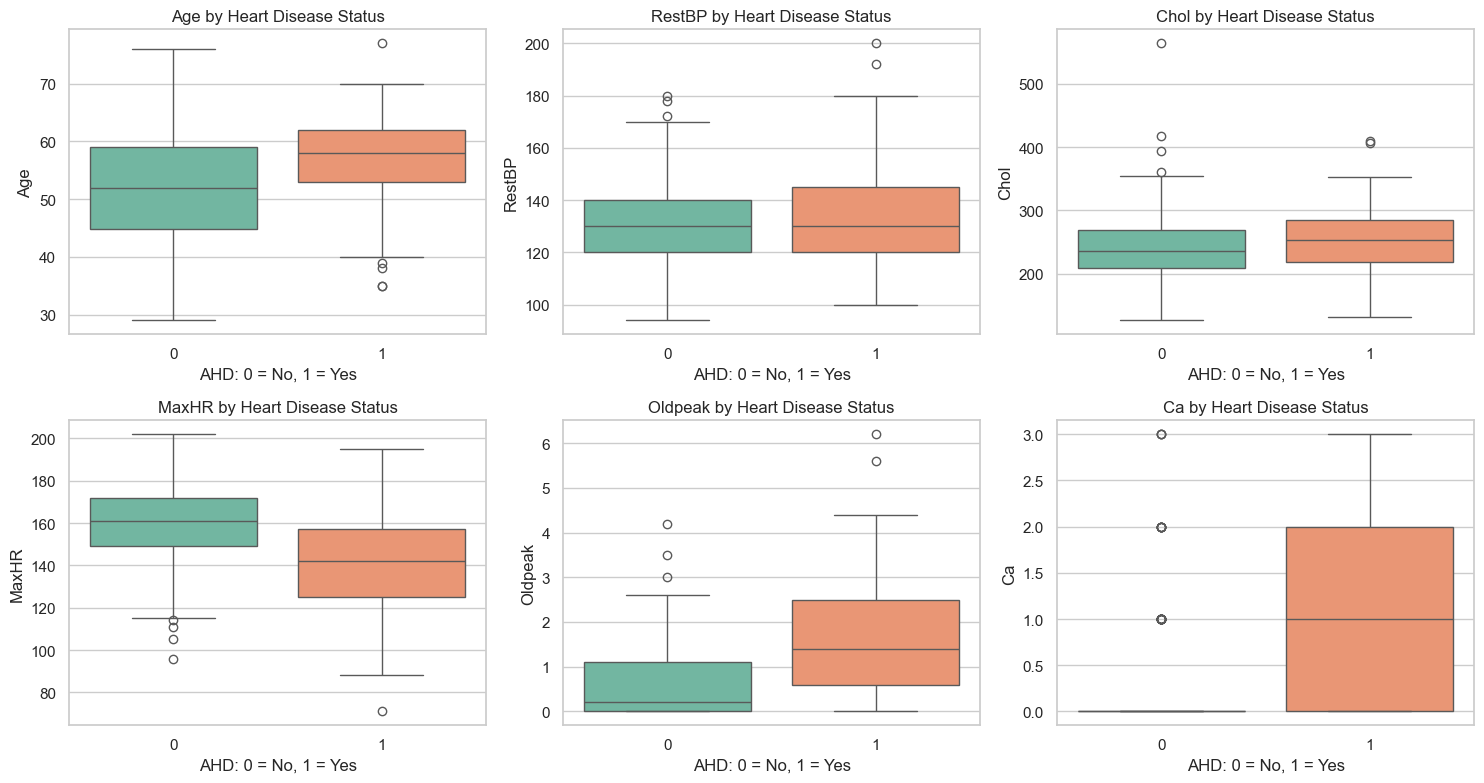

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, feature in zip(axes.ravel(), numeric_features):
    sns.boxplot(
        data=df,
        x="AHD",
        y=feature,
        hue="AHD",
        legend=False,
        ax=ax,
        palette="Set2"
    )

    ax.set_title(f"{feature} by Heart Disease Status")
    ax.set_xlabel("AHD: 0 = No, 1 = Yes")

plt.tight_layout()
plt.show()


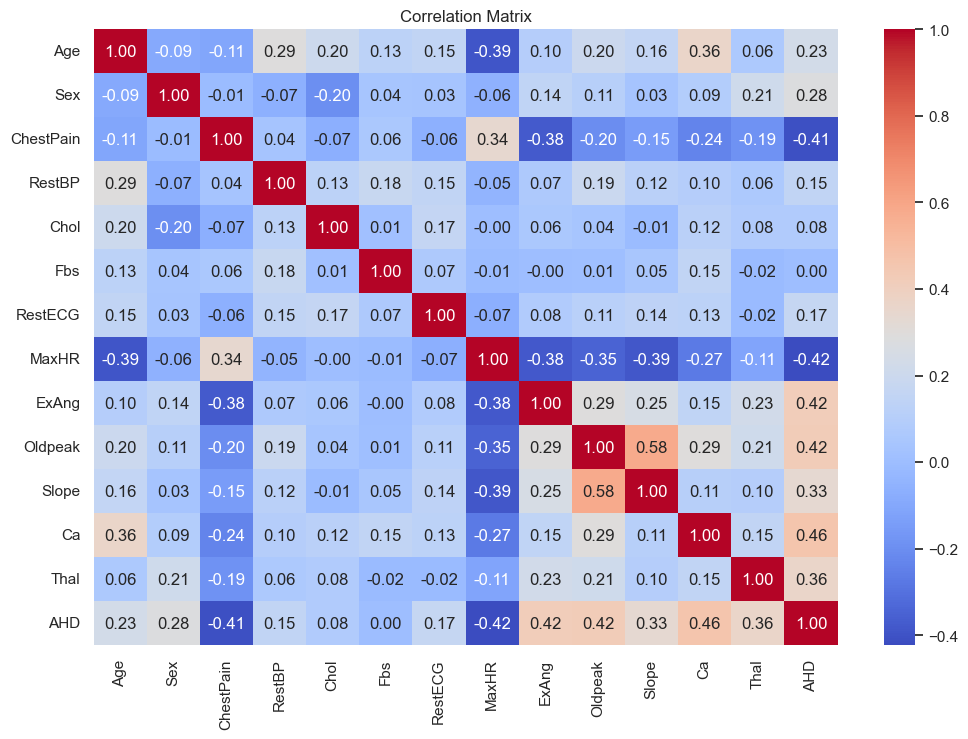

In [16]:
corr_df = df.copy()

for column in corr_df.select_dtypes(include=["string", "object", "category"]).columns:
    corr_df[column] = corr_df[column].astype("category").cat.codes

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()


In [17]:
X = df.drop(columns=["AHD"])
y = df["AHD"]


In [18]:
numeric_features = X.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['Age', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'MaxHR', 'ExAng', 'Oldpeak', 'Slope', 'Ca']
Categorical features: ['Sex', 'ChestPain', 'Thal']


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)



In [21]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)


In [22]:
models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("model", DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Support Vector Machine": Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("model", SVC(
            kernel="rbf",
            probability=True,
            class_weight="balanced",
            random_state=42
        ))
    ])
}


In [23]:
max_depth=4
min_samples_leaf=5

results = []
predictions = {}
probabilities = {}

for model_name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))



                    Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
0     Logistic Regression     0.850      0.852   0.821     0.836    0.944
1           Decision Tree     0.767      0.750   0.750     0.750    0.876
2  Support Vector Machine     0.850      0.852   0.821     0.836    0.950


In [24]:
for model_name in models:
    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    print(classification_report(
        y_test,
        predictions[model_name],
        target_names=["No Disease", "Disease"],
        zero_division=0
    ))



Logistic Regression
              precision    recall  f1-score   support

  No Disease       0.85      0.88      0.86        32
     Disease       0.85      0.82      0.84        28

    accuracy                           0.85        60
   macro avg       0.85      0.85      0.85        60
weighted avg       0.85      0.85      0.85        60


Decision Tree
              precision    recall  f1-score   support

  No Disease       0.78      0.78      0.78        32
     Disease       0.75      0.75      0.75        28

    accuracy                           0.77        60
   macro avg       0.77      0.77      0.77        60
weighted avg       0.77      0.77      0.77        60


Support Vector Machine
              precision    recall  f1-score   support

  No Disease       0.85      0.88      0.86        32
     Disease       0.85      0.82      0.84        28

    accuracy                           0.85        60
   macro avg       0.85      0.85      0.85        60
weighted avg  

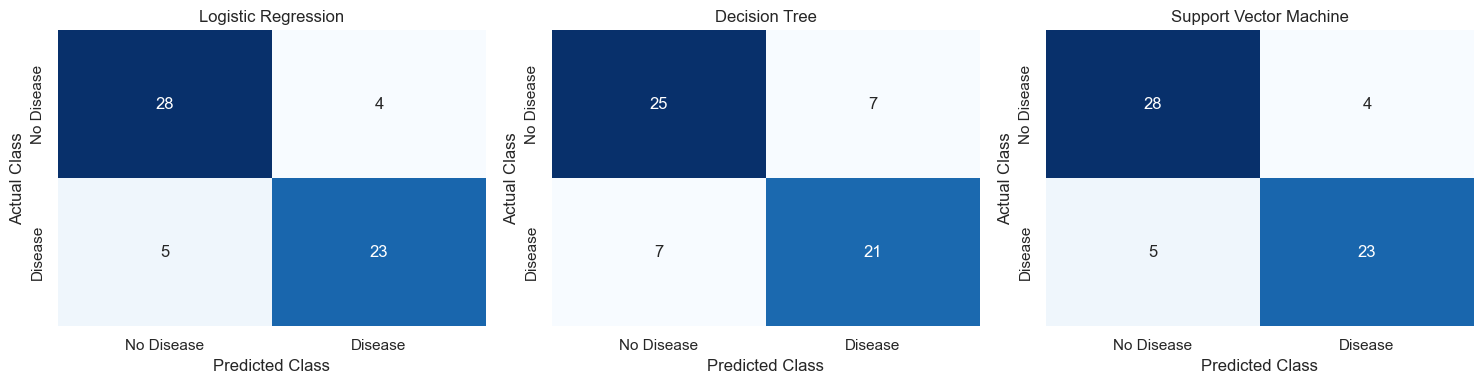

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, model_name in zip(axes, models):
    cm = confusion_matrix(
        y_test,
        predictions[model_name]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    ax.set_xticklabels(["No Disease", "Disease"])
    ax.set_yticklabels(["No Disease", "Disease"])

plt.tight_layout()
plt.show()


<Figure size 800x600 with 0 Axes>

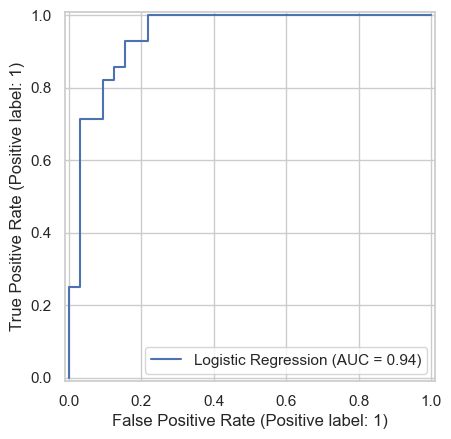

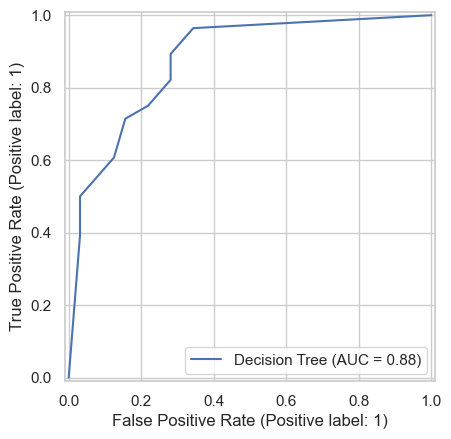

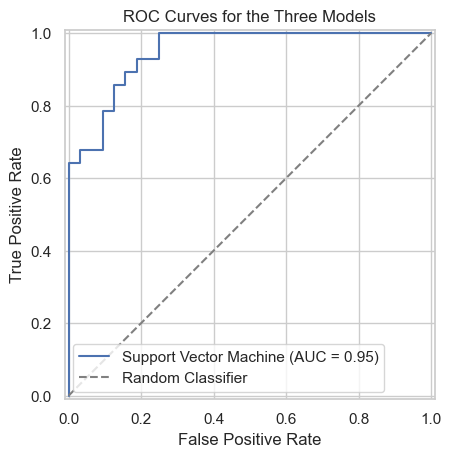

In [26]:
plt.figure(figsize=(8, 6))

for model_name in models:
    RocCurveDisplay.from_predictions(
        y_test,
        probabilities[model_name],
        name=model_name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("ROC Curves for the Three Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()


In [27]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = []

for model_name, model in models.items():
    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": model_name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Precision Mean": scores["test_precision"].mean(),
        "Recall Mean": scores["test_recall"].mean(),
        "F1 Mean": scores["test_f1"].mean(),
        "ROC-AUC Mean": scores["test_roc_auc"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

print(cv_results_df.round(3))


                    Model  Accuracy Mean  Accuracy Std  Precision Mean  \
0     Logistic Regression          0.828         0.054           0.816   
1           Decision Tree          0.767         0.059           0.776   
2  Support Vector Machine          0.808         0.063           0.812   

   Recall Mean  F1 Mean  ROC-AUC Mean  ROC-AUC Std  
0        0.809    0.813         0.897        0.045  
1        0.699    0.731         0.831        0.056  
2        0.766    0.784         0.887        0.045  


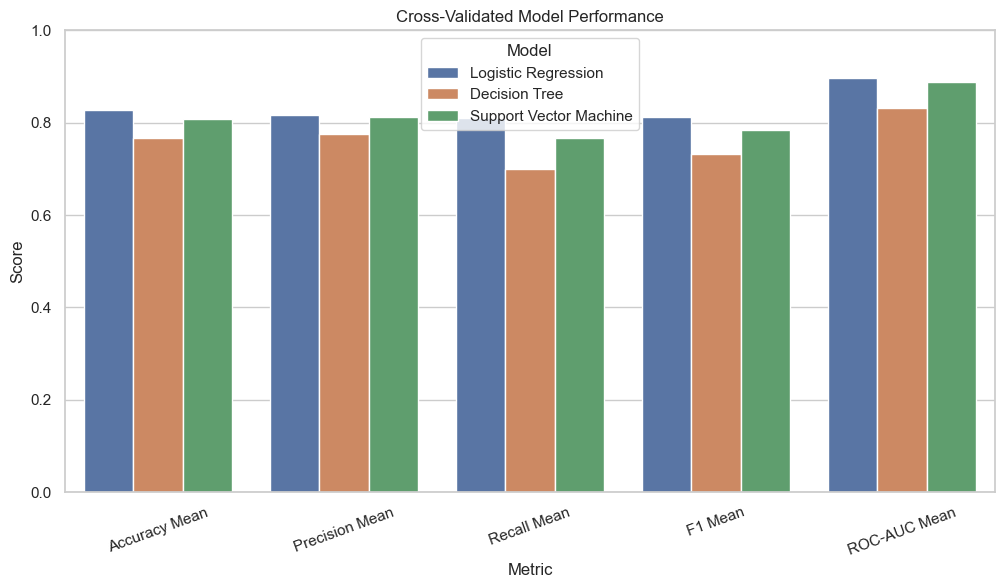

In [28]:
plot_data = cv_results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy Mean",
        "Precision Mean",
        "Recall Mean",
        "F1 Mean",
        "ROC-AUC Mean"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.ylim(0, 1)
plt.title("Cross-Validated Model Performance")
plt.xticks(rotation=20)
plt.legend(title="Model")
plt.show()


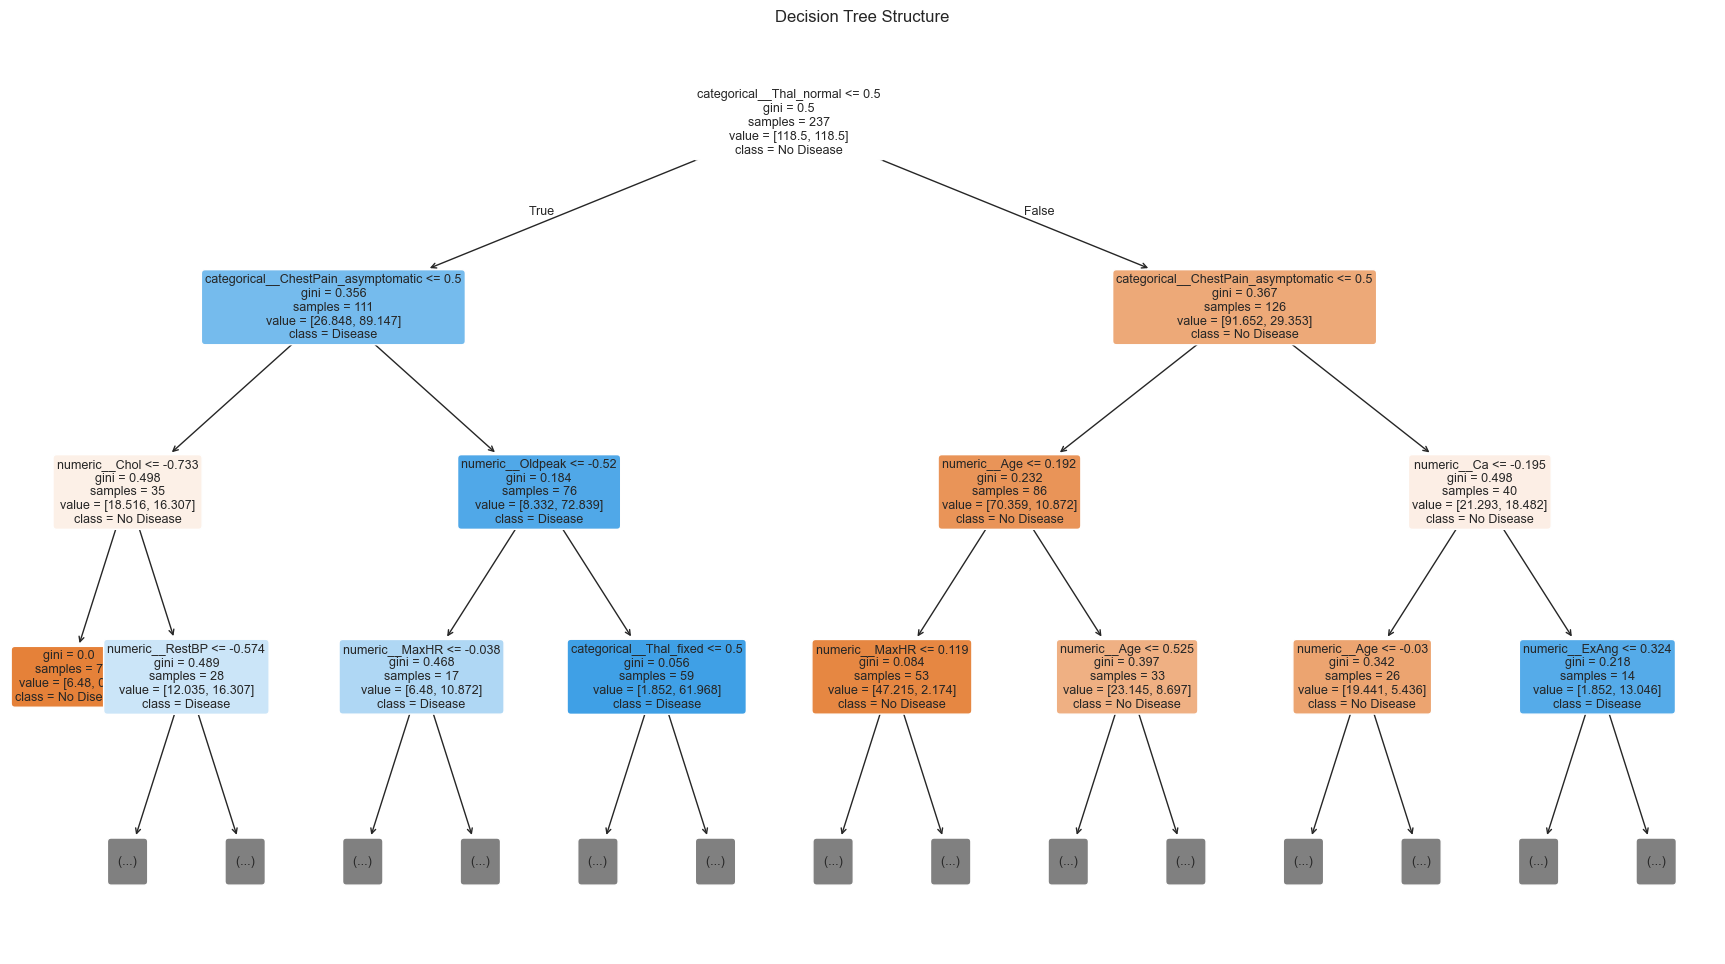

In [29]:
tree_pipeline = models["Decision Tree"]

tree_model = tree_pipeline.named_steps["model"]
tree_preprocessor = tree_pipeline.named_steps["preprocessing"]

feature_names = tree_preprocessor.get_feature_names_out()

plt.figure(figsize=(22, 12))

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=["No Disease", "Disease"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree Structure")
plt.show()


In [30]:
logistic_pipeline = models["Logistic Regression"]

logistic_model = logistic_pipeline.named_steps["model"]
logistic_preprocessor = logistic_pipeline.named_steps["preprocessing"]

logistic_feature_names = (
    logistic_preprocessor.get_feature_names_out()
)

coefficients = pd.DataFrame({
    "Feature": logistic_feature_names,
    "Coefficient": logistic_model.coef_[0]
})

coefficients["Absolute Effect"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    by="Absolute Effect",
    ascending=False
)

print(coefficients.head(15))


                                Feature  Coefficient  Absolute Effect
12  categorical__ChestPain_asymptomatic     1.045832         1.045832
9                           numeric__Ca     0.930847         0.930847
18         categorical__Thal_reversable     0.901003         0.901003
13    categorical__ChestPain_nonanginal    -0.694957         0.694957
17             categorical__Thal_normal    -0.611325         0.611325
10                   categorical__Sex_0    -0.536473         0.536473
11                   categorical__Sex_1     0.534147         0.534147
7                      numeric__Oldpeak     0.438704         0.438704
8                        numeric__Slope     0.437266         0.437266
15       categorical__ChestPain_typical    -0.435714         0.435714
1                       numeric__RestBP     0.384094         0.384094
16              categorical__Thal_fixed    -0.292004         0.292004
4                      numeric__RestECG     0.277594         0.277594
6                   

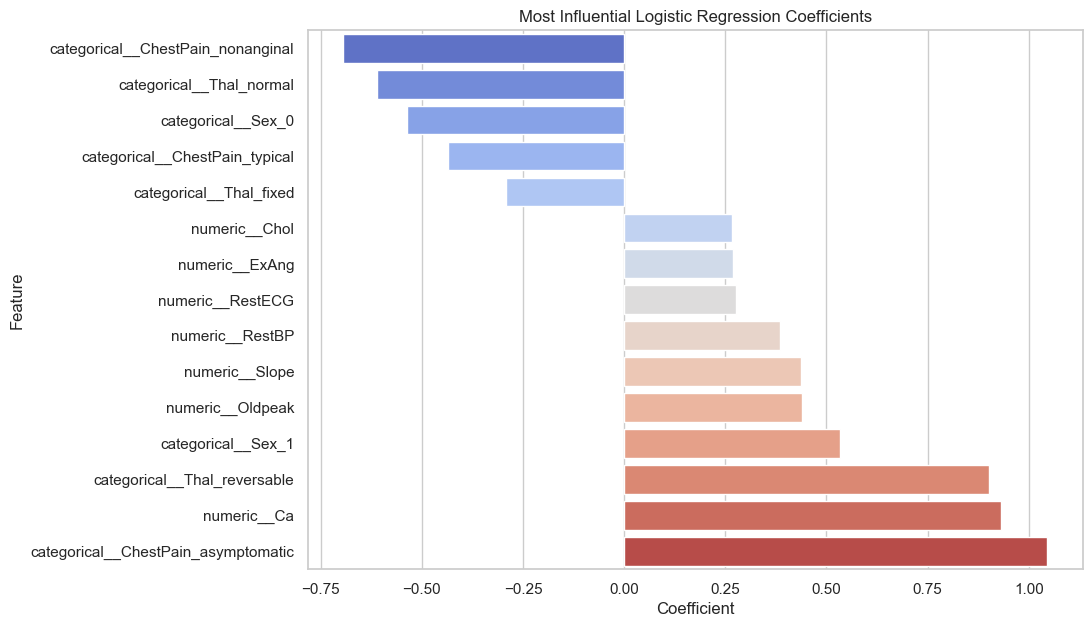

In [31]:
top_coefficients = coefficients.head(15).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_coefficients,
    x="Coefficient",
    y="Feature",
    hue="Feature",
    legend=False,
    palette="coolwarm"
)

plt.title("Most Influential Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.show()


In [32]:
best_model_row = cv_results_df.sort_values(
    by=["ROC-AUC Mean", "Recall Mean"],
    ascending=False
).iloc[0]

print("Recommended model:", best_model_row["Model"])
print("Mean ROC-AUC:", round(best_model_row["ROC-AUC Mean"], 3))
print("Mean Recall:", round(best_model_row["Recall Mean"], 3))


Recommended model: Logistic Regression
Mean ROC-AUC: 0.897
Mean Recall: 0.809


Exception ignored in: <function ResourceTracker.__del__ at 0x109c65bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1066cdbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x109215bc0>
Traceback (most recent call last